# 02｜BTC／ETH：价格趋势和资金费率是两类问题

本书重新计算本机固定批次的 BTC 现货趋势，并分析真实资金费事件。ETH 的交易所 OHLC 尚缺本机快照，补充使用 Coin Metrics 的 USD 参考价格作描述，不把它当成 Binance 可成交价。

In [1]:
from pathlib import Path
import sys, json
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "config/research-playbook.properties").is_file())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from tools.research_playbook.data import load_frame, inventory, data_root, sha
from tools.research_playbook.analysis import plot_style
plot_style()
pd.set_option("display.max_columns", 12)

## 1. 从价格到可交易的时间顺序

信号使用前一天已结束的 K 线，下一天 UTC 开盘执行。200 日均线需要评分前预热。成本是单边 15 bps，包含费用和滑点假设；起始资金 100,000 USDT，现金收益零、无杠杆，末日收盘统一扣平仓费用。数据截至本地快照末日，可能比最新正式库旧。

In [2]:
from tools.research_playbook.analysis import btc_baselines
btc=load_frame("btc_daily")
runs,score=btc_baselines(btc)
display(score[["annualReturn","maxDrawdown","sharpe","tradeCount","cost"]])
print("本次本机窗口末日：",btc.open_time.max())

,annualReturn,maxDrawdown,sharpe,tradeCount,cost
rule,,,,,
hold,0.370687,-0.766293,0.837580,2,1193.611021
trend,0.356992,-0.643687,0.928897,54,32786.395776


本次本机窗口末日： 2026-10-23 00:00:00+00:00


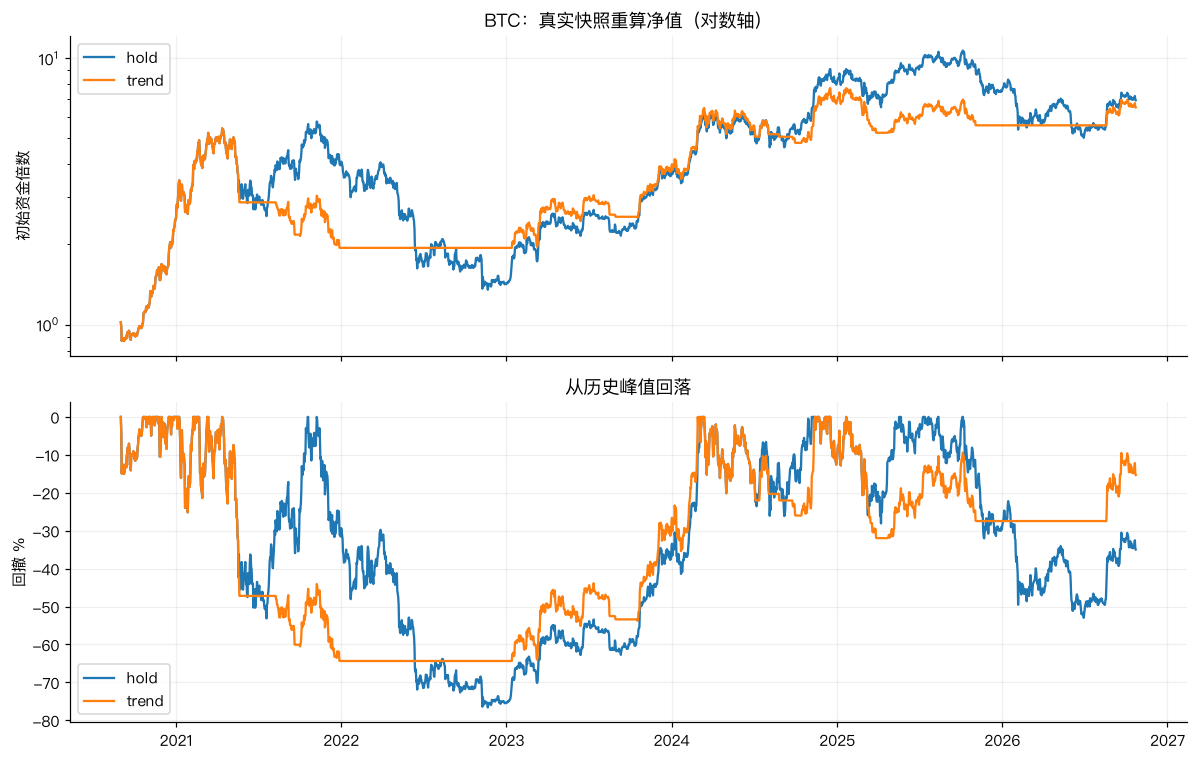

In [3]:
fig,axs=plt.subplots(2,1,figsize=(11,7),sharex=True)
for name,run in runs.items():
    d=run["daily"].set_index("day"); d.index=pd.to_datetime(d.index)
    axs[0].plot(d.index,d.nav/100000,label=name)
    # 初始本金也属于历史峰值，避免第一天亏损被漏掉。
    peak=np.maximum.accumulate(np.r_[100000,d.nav.to_numpy()])[1:]
    axs[1].plot(d.index,(d.nav/peak-1)*100,label=name)
axs[0].set_yscale("log"); axs[0].set_title("BTC：真实快照重算净值（对数轴）"); axs[0].set_ylabel("初始资金倍数")
axs[1].set_title("从历史峰值回落"); axs[1].set_ylabel("回撤 %")
for ax in axs: ax.legend()
plt.tight_layout(); plt.show()

**读图：** 对数轴上相同垂直距离表示相同倍数变化。下图更接近持有体验：回撤深度和持续时间都重要。趋势规则可能在快速反弹时处于现金，也可能反复进出支付费用；更平稳不等于更赚钱。这里是开发回放，不是新留出期。

In [4]:
trades=runs["trend"]["trades"]
rebalance_trades=trades[trades.event=="rebalance"].copy()
assert (pd.to_datetime(rebalance_trades.signalLastBarClosedAt,utc=True)<=pd.to_datetime(rebalance_trades.executionAt,utc=True)).all()
display(trades.head(8))

,day,symbol,executionAt,signalLastBarClosedAt,price,notionalChange,unitsChange,cost,event
0,2020-09-01,BTCUSDT,2020-09-01T00:00:00+00:00,2020-09-01T00:00:00+00:00,11649.51,99850.224663,8.571195,149.775337,rebalance
1,2021-05-20,BTCUSDT,2021-05-20T00:00:00+00:00,2021-05-20T00:00:00+00:00,36671.23,-314316.272029,-8.571195,471.474408,rebalance
2,2021-05-21,BTCUSDT,2021-05-21T00:00:00+00:00,2021-05-21T00:00:00+00:00,40525.39,313374.735518,7.732800,470.062103,rebalance
3,2021-05-22,BTCUSDT,2021-05-22T00:00:00+00:00,2021-05-22T00:00:00+00:00,37263.35,-288150.032628,-7.732800,432.225049,rebalance
4,2021-08-10,BTCUSDT,2021-08-10T00:00:00+00:00,2021-08-10T00:00:00+00:00,46248.87,287286.877263,6.211760,430.930316,rebalance
5,2021-08-13,BTCUSDT,2021-08-13T00:00:00+00:00,2021-08-13T00:00:00+00:00,44400.06,-275802.513395,-6.211760,413.703770,rebalance
6,2021-08-14,BTCUSDT,2021-08-14T00:00:00+00:00,2021-08-14T00:00:00+00:00,47799.99,274976.345108,5.752644,412.464518,rebalance
7,2021-08-18,BTCUSDT,2021-08-18T00:00:00+00:00,2021-08-18T00:00:00+00:00,44695.95,-257119.906764,-5.752644,385.679860,rebalance


边界上收盘与下一根开盘可能共享同一 UTC 时刻。上述检查只证明没有使用未来 K 线，不能证明真实系统能零延迟成交；费用与滑点是情景假设。

## 2. 真实资金费事件，不假定固定八小时

费率按事件给出，小数 0.0001 等于 1 bp。正费率通常表示多头向空头支付。下面汇总已观察事件，不计算“每八小时乘三再年化”，也不把累计费率当成完整套利收益。

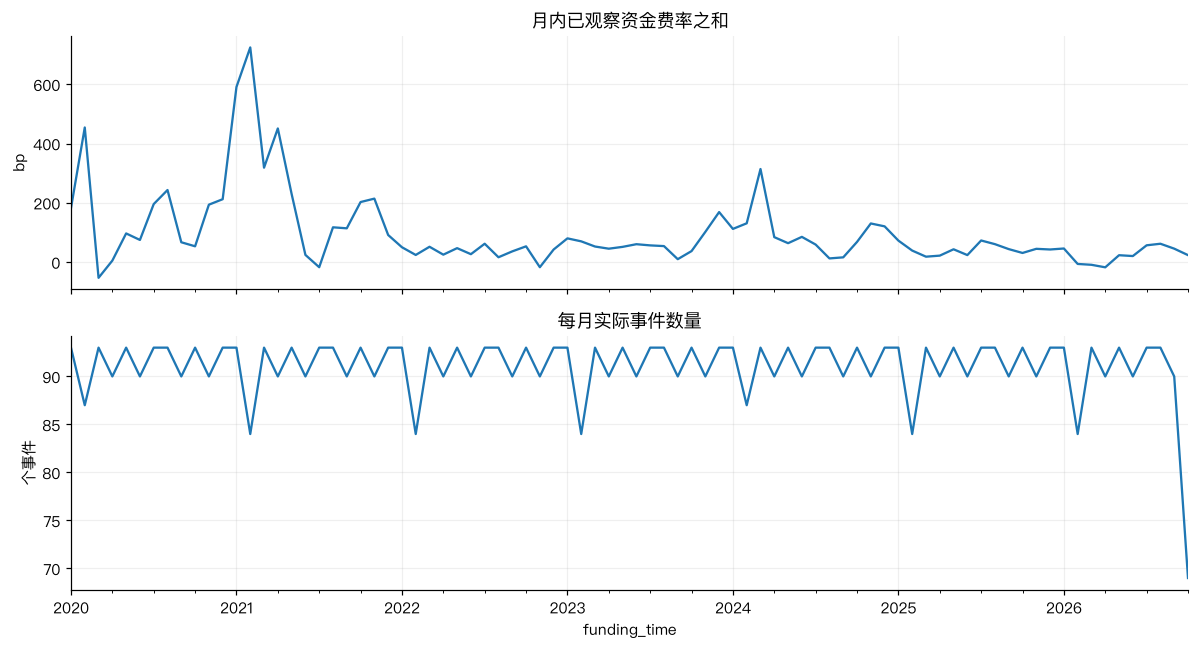

,事件数,已观察费率和_bp
funding_time,,
2026-07-01 00:00:00+00:00,93,56.5608
2026-08-01 00:00:00+00:00,93,61.8288
2026-09-01 00:00:00+00:00,90,45.2757
2026-10-01 00:00:00+00:00,69,23.4301


In [5]:
fund=load_frame("btc_funding").set_index("funding_time").sort_index()
monthly=pd.DataFrame({"事件数":fund.funding_rate.resample("MS").count(),"已观察费率和_bp":fund.funding_rate.resample("MS").sum(min_count=1)*10000})
fig,axs=plt.subplots(2,1,figsize=(11,6),sharex=True)
monthly["已观察费率和_bp"].plot(ax=axs[0],title="月内已观察资金费率之和")
monthly["事件数"].plot(ax=axs[1],title="每月实际事件数量")
axs[0].set_ylabel("bp"); axs[1].set_ylabel("个事件"); plt.tight_layout(); plt.show()
display(monthly.tail(4))

**读图：** 事件数量较少可能是样本首尾截断、结算频率变化或缺数据，不能只凭这幅图定性。实际资金费现金额还取决于结算时名义本金；套利还涉及两腿成交、借币、基差变化、保证金和强平。现有多表缺口没有因此消失。

## 3. ETH：补充描述，保持来源边界

Coin Metrics 的 `PriceUSD` 是美元参考价，和 BTCUSDT 的交易所 K 线不是同一种价格。只画共同有效日期的归一化价格，不拼接到原交易所回放。

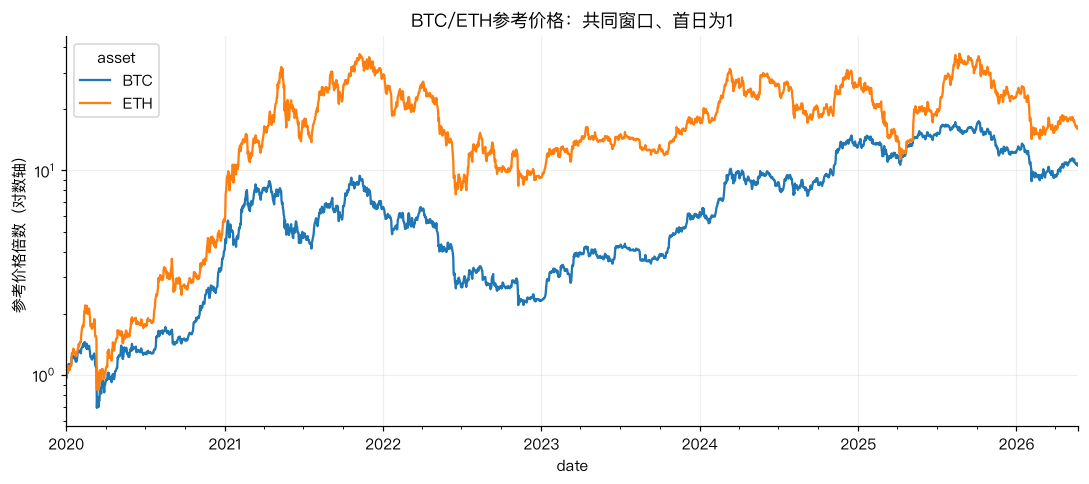

共同有效日期： 2020-01-01 00:00:00+00:00 至 2026-05-23 00:00:00+00:00


In [6]:
chain=load_frame("onchain")
prices=chain.pivot(index="date",columns="asset",values="PriceUSD").loc["2020-01-01":].dropna()
(prices/prices.iloc[0]).plot(logy=True,title="BTC/ETH参考价格：共同窗口、首日为1")
plt.ylabel("参考价格倍数（对数轴）"); plt.tight_layout(); plt.show()
print("共同有效日期：",prices.index.min(),"至",prices.index.max())

**练习：** 为什么不能把两个来源的重叠日期当成两份独立样本？因为它们主要观测同一个市场过程。来源对照有助于发现差异，但不增加独立市场历史。